In [1]:
import io
import pathlib
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

sys.path.insert(0, str(pathlib.Path.cwd().parent))  # repo root → makes `src` importable

from src.config import CLASS_NAMES, SEED, TARGET, TEST_DATASET_PATH, TEXT_COLUMN, TRAIN_DATASET_PATH
from src.data.io import download_medical_abstracts, read_dataset

sns.set_theme(style="whitegrid")
SERIES_1, SERIES_2 = "#2a78d6", "#eb6834"  # categorical slots 1-2 (blue, orange)

In [2]:
# Load — official train/test split of the Medical Abstracts TC Corpus
download_medical_abstracts()  # no-op when the CSVs are already in data/raw
train_raw = read_dataset(TRAIN_DATASET_PATH)
test_raw = read_dataset(TEST_DATASET_PATH)

print(f"Train raw shape: {train_raw.shape}")
print(f"Test  raw shape: {test_raw.shape}")
print(f"Nulls          : {train_raw.isna().sum().sum() + test_raw.isna().sum().sum()}")
display(train_raw.head())

Train raw shape: (11550, 2)
Test  raw shape: (2888, 2)
Nulls          : 0


,condition_label,medical_abstract
0,5,Tissue changes around loose prostheses. A cani...
1,1,Neuropeptide Y and neuron-specific enolase lev...
2,2,"Sexually transmitted diseases of the colon, re..."
3,1,Lipolytic factors associated with murine and h...
4,3,Does carotid restenosis predict an increased r...


,train,test
condition_label,,
neoplasms,21.9%,21.9%
digestive system diseases,10.3%,10.4%
nervous system diseases,13.3%,13.3%
cardiovascular diseases,21.1%,21.1%
general pathological conditions,33.3%,33.3%


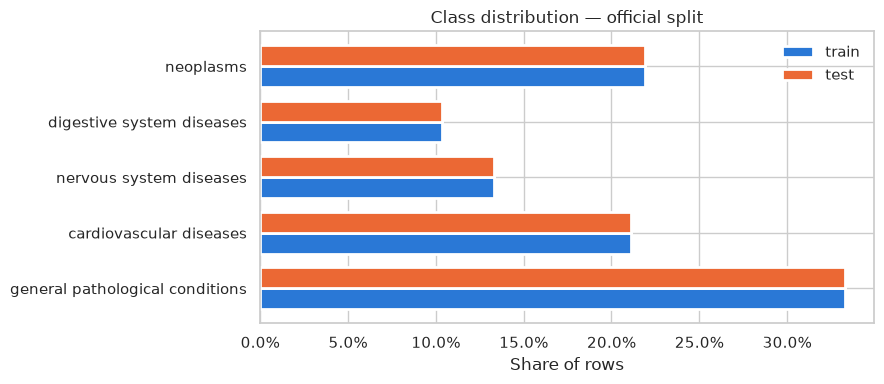

In [3]:
# Class distribution — official train vs test split
dist = pd.DataFrame({
    "train": train_raw[TARGET].value_counts(normalize=True),
    "test": test_raw[TARGET].value_counts(normalize=True),
}).sort_index().rename(index=CLASS_NAMES)
display(dist.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(9, 4))
dist[::-1].plot.barh(ax=ax, color=[SERIES_1, SERIES_2], width=0.75, edgecolor="white", linewidth=2)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Share of rows")
ax.set_ylabel("")
ax.set_title("Class distribution — official split")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [4]:
# Label-integrity audit — the corpus is multi-label flattened into rows:
# the same abstract appears once per condition it was tagged with
all_rows = pd.concat([train_raw.assign(split="train"), test_raw.assign(split="test")])
labels_per_text = all_rows.groupby(TEXT_COLUMN)[TARGET].nunique()
ambiguous_texts = set(labels_per_text[labels_per_text > 1].index)
shared_texts = set(train_raw[TEXT_COLUMN]) & set(test_raw[TEXT_COLUMN])

print(f"Unique abstracts                 : {len(labels_per_text):,}")
print(f"Labels per abstract              : {labels_per_text.value_counts().sort_index().to_dict()}")
print(f"Exact (text, label) duplicates   : {all_rows.duplicated([TEXT_COLUMN, TARGET]).sum()}")
print(f"Train rows with multi-label text : {train_raw[TEXT_COLUMN].isin(ambiguous_texts).sum():,}"
      f" ({train_raw[TEXT_COLUMN].isin(ambiguous_texts).mean():.1%})")
print(f"Test rows with multi-label text  : {test_raw[TEXT_COLUMN].isin(ambiguous_texts).sum():,}"
      f" ({test_raw[TEXT_COLUMN].isin(ambiguous_texts).mean():.1%})")
# With zero exact duplicates, every test abstract that also appears in train carries a
# *different* label there — a model that learned the train label is graded wrong on it
print(f"Test rows whose text is in train : {test_raw[TEXT_COLUMN].isin(shared_texts).sum():,}"
      f" ({test_raw[TEXT_COLUMN].isin(shared_texts).mean():.1%}), always with a different label")

combos = (
    all_rows[all_rows[TEXT_COLUMN].isin(ambiguous_texts)]
    .groupby(TEXT_COLUMN)[TARGET]
    .agg(lambda s: " + ".join(CLASS_NAMES[c] for c in sorted(set(s))))
    .value_counts()
    .head(10)
)
display(combos.to_frame("abstracts"))

Unique abstracts                 : 11,227
Labels per abstract              : {1: 8298, 2: 2653, 3: 270, 4: 6}
Exact (text, label) duplicates   : 0
Train rows with multi-label text : 4,943 (42.8%)
Test rows with multi-label text  : 1,197 (41.4%)
Test rows whose text is in train : 1,010 (35.0%), always with a different label


,abstracts
condition_label,
cardiovascular diseases + general pathological conditions,738
neoplasms + general pathological conditions,486
digestive system diseases + general pathological conditions,475
nervous system diseases + general pathological conditions,446
neoplasms + nervous system diseases,139
neoplasms + digestive system diseases,134
nervous system diseases + cardiovascular diseases,114
nervous system diseases + cardiovascular diseases + general pathological conditions,72
neoplasms + cardiovascular diseases,67


In [5]:
# Single-label dataset — drop every abstract tagged with more than one condition
# (identical input with different targets is irreducible noise for a single-label classifier).
# This also removes every train/test text overlap. See NLP_experiments_decisions.md
train_df = train_raw[~train_raw[TEXT_COLUMN].isin(ambiguous_texts)].reset_index(drop=True)
test_df = test_raw[~test_raw[TEXT_COLUMN].isin(ambiguous_texts)].reset_index(drop=True)

assert not set(train_df[TEXT_COLUMN]) & set(test_df[TEXT_COLUMN]), "train/test text overlap"
assert not pd.concat([train_df, test_df])[TEXT_COLUMN].duplicated().any(), "duplicated abstracts"

X_train, y_train = train_df[TEXT_COLUMN], train_df[TARGET]
X_test, y_test = test_df[TEXT_COLUMN], test_df[TARGET]

print(f"Train shape : {train_df.shape}  (dropped {len(train_raw) - len(train_df):,} rows)")
print(f"Test  shape : {test_df.shape}  (dropped {len(test_raw) - len(test_df):,} rows)")
display(
    pd.DataFrame({
        "train": y_train.value_counts(normalize=True),
        "test": y_test.value_counts(normalize=True),
    }).sort_index().rename(index=CLASS_NAMES).style.format("{:.1%}")
)

Train shape : (6607, 2)  (dropped 4,943 rows)
Test  shape : (1691, 2)  (dropped 1,197 rows)


,train,test
condition_label,,
neoplasms,26.5%,26.2%
digestive system diseases,8.4%,8.3%
nervous system diseases,12.5%,13.3%
cardiovascular diseases,23.5%,24.1%
general pathological conditions,29.1%,28.0%


,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
cardiovascular diseases,1553.0,205.0,78.0,28.0,151.0,211.0,261.0,578.0
digestive system diseases,558.0,179.0,71.0,42.0,125.0,181.0,226.0,400.0
general pathological conditions,1920.0,173.0,74.0,31.0,118.0,164.0,223.0,471.0
neoplasms,1752.0,177.0,75.0,26.0,125.0,174.0,224.0,422.0
nervous system diseases,824.0,165.0,71.0,31.0,114.0,156.0,216.0,596.0


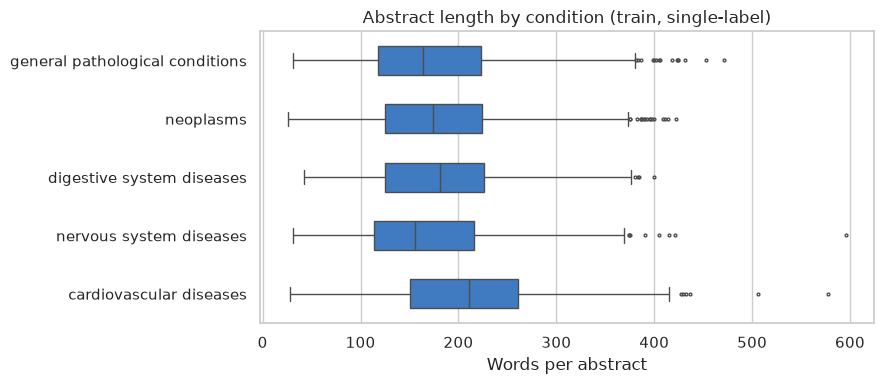

In [6]:
# Abstract length (words) per condition — informs TF-IDF settings and the API payload limit
lengths = train_df.assign(
    words=train_df[TEXT_COLUMN].str.split().str.len(),
    condition=train_df[TARGET].map(CLASS_NAMES),
)
display(lengths.groupby("condition")["words"].describe().round(0))

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=lengths, x="words", y="condition", color=SERIES_1, width=0.5, fliersize=2, ax=ax)
ax.set_xlabel("Words per abstract")
ax.set_ylabel("")
ax.set_title("Abstract length by condition (train, single-label)")
plt.tight_layout()
plt.show()

In [7]:
def compute_metrics(y_true, y_pred, model_name="Model"):
    """Return a labelled Series of multiclass classification metrics."""
    return pd.Series({
        "Accuracy"          : accuracy_score(y_true, y_pred),
        "F1 (macro)"        : f1_score(y_true, y_pred, average="macro"),
        "F1 (weighted)"     : f1_score(y_true, y_pred, average="weighted"),
        "Precision (macro)" : precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)"    : recall_score(y_true, y_pred, average="macro", zero_division=0),
    }, name=model_name)

In [8]:
# Candidate models — every classifier sees the same TF-IDF representation, so score
# differences come from the classifier alone (unigrams + bigrams, sublinear TF,
# English stop words, terms seen in fewer than 2 abstracts dropped)
TFIDF_PARAMS = {
    "lowercase": True,
    "stop_words": "english",
    "ngram_range": (1, 2),
    "min_df": 2,
    "sublinear_tf": True,
}

def make_pipeline(classifier):
    return Pipeline([("tfidf", TfidfVectorizer(**TFIDF_PARAMS)), ("clf", clone(classifier))])

candidates = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Multinomial NB"       : MultinomialNB(),
    "Logistic Regression"  : LogisticRegression(max_iter=1000, random_state=SEED),
    "Linear SVM"           : LinearSVC(random_state=SEED),
    "Random Forest"        : RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
}

# Model selection = 5-fold stratified CV on train (macro-F1: classes are imbalanced);
# the held-out test set is only used to report the final numbers
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, classifier in candidates.items():
    scores = cross_validate(
        make_pipeline(classifier), X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"]
    )
    cv_rows.append({
        "model"           : name,
        "cv_f1_macro"     : scores["test_f1_macro"].mean(),
        "cv_f1_macro_std" : scores["test_f1_macro"].std(),
        "cv_accuracy"     : scores["test_accuracy"].mean(),
        "fit_time_s"      : scores["fit_time"].mean(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("cv_f1_macro", ascending=False)
display(cv_results.round(4))

,cv_f1_macro,cv_f1_macro_std,cv_accuracy,fit_time_s
model,,,,
Linear SVM,0.7982,0.0080,0.8132,0.9674
Logistic Regression,0.7249,0.0042,0.7702,9.0610
Random Forest,0.6987,0.0035,0.7506,3.8895
Multinomial NB,0.4734,0.0036,0.6784,1.6322
Dummy (most frequent),0.0901,0.0000,0.2906,0.9348


In [9]:
# Fit on the full train set, score on the held-out test set and measure inference cost:
# single-request latency (one abstract per predict call, as the API will serve it) and
# serialized pipeline size (what ships in the Docker image)
N_LATENCY_SAMPLES = 300
latency_texts = X_test.sample(N_LATENCY_SAMPLES, random_state=SEED).tolist()

def single_request_latency_ms(pipeline, texts):
    """p50 / p95 wall time (ms) of predicting one text at a time."""
    pipeline.predict(texts[:5])  # warm-up
    timings = []
    for text in texts:
        start = time.perf_counter()
        pipeline.predict([text])
        timings.append((time.perf_counter() - start) * 1000)
    return np.percentile(timings, [50, 95])

def serialized_size_mb(pipeline):
    buffer = io.BytesIO()
    joblib.dump(pipeline, buffer)
    return buffer.getbuffer().nbytes / 1e6

fitted, test_metrics, cost_rows = {}, [], []
for name, classifier in candidates.items():
    pipe = make_pipeline(classifier).fit(X_train, y_train)
    if "clf__n_jobs" in pipe.get_params():
        pipe.set_params(clf__n_jobs=1)  # serving: one request per worker thread
    fitted[name] = pipe
    test_metrics.append(compute_metrics(y_test, pipe.predict(X_test), name))
    p50, p95 = single_request_latency_ms(pipe, latency_texts)
    cost_rows.append({
        "model"          : name,
        "latency_p50_ms" : p50,
        "latency_p95_ms" : p95,
        "size_mb"        : serialized_size_mb(pipe),
    })

comparison = pd.concat(test_metrics, axis=1)
cost = pd.DataFrame(cost_rows).set_index("model")
print(f"TF-IDF vocabulary size: {len(fitted['Logistic Regression'].named_steps['tfidf'].vocabulary_):,}")
print("=== Test-set metrics ===")
display(comparison.round(4))
print("=== Inference cost ===")
display(cost.round(2))

TF-IDF vocabulary size: 81,472
=== Test-set metrics ===


,Dummy (most frequent),Multinomial NB,Logistic Regression,Linear SVM,Random Forest
Accuracy,0.2803,0.6606,0.7688,0.8179,0.7398
F1 (macro),0.0876,0.4644,0.7443,0.8149,0.7052
F1 (weighted),0.1227,0.5963,0.7674,0.8178,0.7331
Precision (macro),0.0561,0.6236,0.8159,0.8283,0.7959
Recall (macro),0.2000,0.5087,0.7127,0.8043,0.6749


=== Inference cost ===


,latency_p50_ms,latency_p95_ms,size_mb
model,,,
Dummy (most frequent),0.48,0.70,2.29
Multinomial NB,1.04,1.38,8.81
Logistic Regression,0.62,0.91,5.55
Linear SVM,0.60,0.81,5.55
Random Forest,20.25,25.90,125.76


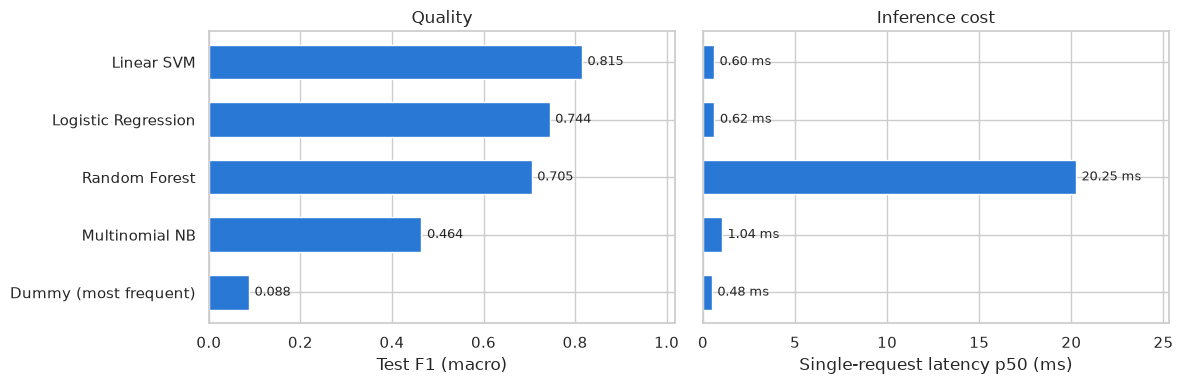

In [10]:
# Quality vs cost — test macro-F1 and single-request p50 latency, one panel each
# (different units, so separate axes rather than a dual-axis chart)
order = comparison.loc["F1 (macro)"].sort_values().index

fig, (ax_f1, ax_lat) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, values, fmt, xlabel in [
    (ax_f1, comparison.loc["F1 (macro)", order], "{:.3f}", "Test F1 (macro)"),
    (ax_lat, cost.loc[order, "latency_p50_ms"], "{:.2f} ms", "Single-request latency p50 (ms)"),
]:
    bars = ax.barh(order, values, color=SERIES_1, height=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=4, fontsize=9)
    ax.set_xlim(0, values.max() * 1.25)
    ax.set_xlabel(xlabel)
ax_f1.set_title("Quality")
ax_lat.set_title("Inference cost")
plt.tight_layout()
plt.show()

=== Linear SVM ===
                                 precision    recall  f1-score   support

                      neoplasms      0.860     0.887     0.873       443
      digestive system diseases      0.867     0.787     0.825       141
        nervous system diseases      0.820     0.707     0.759       225
        cardiovascular diseases      0.873     0.873     0.873       408
general pathological conditions      0.722     0.768     0.744       474

                       accuracy                          0.818      1691
                      macro avg      0.828     0.804     0.815      1691
                   weighted avg      0.820     0.818     0.818      1691



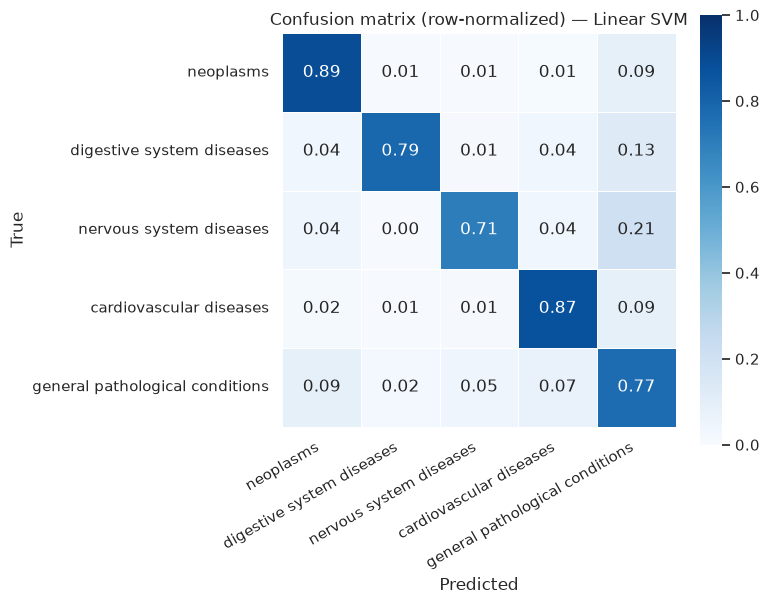

In [11]:
# Best model (by CV macro-F1, excluding the Dummy) — per-class report + confusion matrix
best_name = cv_results.drop(index="Dummy (most frequent)").index[0]
best_pipe = fitted[best_name]
y_pred_best = best_pipe.predict(X_test)
class_labels = [CLASS_NAMES[c] for c in sorted(CLASS_NAMES)]

print(f"=== {best_name} ===")
print(classification_report(y_test, y_pred_best, target_names=class_labels, digits=3))

cm = confusion_matrix(y_test, y_pred_best, labels=sorted(CLASS_NAMES), normalize="true")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True,
    linewidths=0.5, xticklabels=class_labels, yticklabels=class_labels, ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Confusion matrix (row-normalized) — {best_name}")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [12]:
# Top TF-IDF terms per condition — Logistic Regression coefficients (interpretable baseline)
lr_pipe = fitted["Logistic Regression"]
vocab = lr_pipe.named_steps["tfidf"].get_feature_names_out()
coefs = lr_pipe.named_steps["clf"].coef_

top_terms = pd.DataFrame({
    CLASS_NAMES[label]: vocab[np.argsort(coefs[i])[::-1][:12]]
    for i, label in enumerate(lr_pipe.named_steps["clf"].classes_)
})
display(top_terms)

,neoplasms,digestive system diseases,nervous system diseases,cardiovascular diseases,general pathological conditions
0,cancer,cirrhosis,brain,hypertension,postoperative
1,tumor,esophageal,pain,coronary,hemorrhage
2,carcinoma,liver,cerebral,myocardial,acute
3,tumors,diarrhea,seizures,heart,chronic
4,cell,gastric,headache,artery,recurrent
5,cells,bowel,stroke,ventricular,deletion
6,leukemia,gastrointestinal,nerve,aortic,bleeding
7,malignant,gallbladder,motor,cardiac,infection
8,melanoma,hepatitis,migraine,pressure,respiratory
9,breast,biliary,sleep,hypertensive,inflammatory


In [13]:
# Why the single-label cleaning matters — same best pipeline trained on the official
# (flattened multi-label) train split, evaluated on both test versions
raw_pipe = make_pipeline(candidates[best_name]).fit(train_raw[TEXT_COLUMN], train_raw[TARGET])

cleaning_impact = pd.concat([
    compute_metrics(test_raw[TARGET], raw_pipe.predict(test_raw[TEXT_COLUMN]), "raw train → raw test"),
    compute_metrics(y_test, raw_pipe.predict(X_test), "raw train → clean test"),
    comparison[best_name].rename("clean train → clean test"),
], axis=1)
display(cleaning_impact.round(4))

,raw train → raw test,raw train → clean test,clean train → clean test
Accuracy,0.5048,0.8108,0.8179
F1 (macro),0.5011,0.8086,0.8149
F1 (weighted),0.5040,0.8116,0.8178
Precision (macro),0.5052,0.8304,0.8283
Recall (macro),0.4983,0.7930,0.8043


In [14]:
# MLflow tracking — log this notebook's runs to the shared store
# (same sqlite backend + experiment the training pipeline will use;
#  runs are tagged source=NLP_experiments.ipynb to distinguish them from pipeline runs)
import mlflow

from src.config import EXPERIMENT_NAME, MLFLOW_TRACKING_URI

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

for name, pipe in fitted.items():
    with mlflow.start_run(run_name=name):
        mlflow.set_tags({"source": "NLP_experiments.ipynb", "dataset": "medical_abstracts_single_label"})
        mlflow.log_params({
            "model_type": type(pipe.named_steps["clf"]).__name__,
            **{f"tfidf_{k}": v for k, v in TFIDF_PARAMS.items()},
            "vocab_size": len(pipe.named_steps["tfidf"].vocabulary_),
            "n_train": len(X_train),
            "n_test": len(X_test),
        })
        metrics = {
            "accuracy"       : comparison.loc["Accuracy", name],
            "f1_macro"       : comparison.loc["F1 (macro)", name],
            "f1_weighted"    : comparison.loc["F1 (weighted)", name],
            "cv_f1_macro"    : cv_results.loc[name, "cv_f1_macro"],
            "latency_p50_ms" : cost.loc[name, "latency_p50_ms"],
            "latency_p95_ms" : cost.loc[name, "latency_p95_ms"],
            "model_size_mb"  : cost.loc[name, "size_mb"],
        }
        mlflow.log_metrics(metrics)
        print(f"logged {name}: { {k: round(v, 4) for k, v in metrics.items()} }")

2026/10/06 22:28:47 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/06 22:28:47 INFO mlflow.store.db.utils: Updating database tables


2026/10/06 22:28:48 INFO mlflow.tracking.fluent: Experiment with name 'medical-abstracts-nlp' does not exist. Creating a new experiment.


logged Dummy (most frequent): {'accuracy': np.float64(0.2803), 'f1_macro': np.float64(0.0876), 'f1_weighted': np.float64(0.1227), 'cv_f1_macro': np.float64(0.0901), 'latency_p50_ms': np.float64(0.4809), 'latency_p95_ms': np.float64(0.6974), 'model_size_mb': np.float64(2.2921)}
logged Multinomial NB: {'accuracy': np.float64(0.6606), 'f1_macro': np.float64(0.4644), 'f1_weighted': np.float64(0.5963), 'cv_f1_macro': np.float64(0.4734), 'latency_p50_ms': np.float64(1.0382), 'latency_p95_ms': np.float64(1.3769), 'model_size_mb': np.float64(8.8101)}
logged Logistic Regression: {'accuracy': np.float64(0.7688), 'f1_macro': np.float64(0.7443), 'f1_weighted': np.float64(0.7674), 'cv_f1_macro': np.float64(0.7249), 'latency_p50_ms': np.float64(0.6192), 'latency_p95_ms': np.float64(0.9108), 'model_size_mb': np.float64(5.5513)}
logged Linear SVM: {'accuracy': np.float64(0.8179), 'f1_macro': np.float64(0.8149), 'f1_weighted': np.float64(0.8178), 'cv_f1_macro': np.float64(0.7982), 'latency_p50_ms': np.